# Office domain: Certified-RM-VI vs. standard (SFOLS) CCS

In [1]:
import os
os.environ["WANDB_MODE"] = "disabled"

import sys
OKB_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "RM", "sf-fsa-vi"))
for root in (OKB_ROOT, SF_FSA_VI_ROOT):
    if root not in sys.path:
        sys.path.insert(0, root)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import wandb
wandb.init(mode="disabled")

import gym as old_gym
import gymnasium as gym
from gymnasium import spaces
import envs  # noqa: F401 -- registers Office-v0 in old gym

from rl.successor_features.ols import OLS
from rl.utils.utils import seed_everything

%matplotlib inline

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/flax/configurations.py:42: DeprecationWarning: jax.config.define_bool_state is deprecated. Please use other libraries for configuration instead.
  return jax_config.define_bool_state('flax_' + name, default, help)


In [2]:
SEED = 0
GAMMA = 0.99
ADD_OBJ_TO_START = True
PHI_OBJ_TYPES = ["C1", "C2", "O1", "O2", "M1", "M2"]

seed_everything(SEED)

In [3]:
class OfficeGymnasiumEnv(gym.Env):
    """Wraps sf-fsa-vi's old-gym `Office-v0` so it satisfies OKB's gymnasium contract."""

    def __init__(self, add_obj_to_start=True, random_act_prob=0.0):
        self._env = old_gym.make("Office-v0", add_obj_to_start=add_obj_to_start, random_act_prob=random_act_prob)
        self.core = self._env.unwrapped
        self.height, self.width = self.core.height, self.core.width

        self.action_space = spaces.Discrete(self.core.action_space.n)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(2,), dtype=np.float32)

        self.reward_dim = self.core.feat_dim
        self.reward_space = spaces.Box(low=0.0, high=1.0, shape=(self.reward_dim,), dtype=np.float32)

    def _normalize(self, obs):
        return np.array([obs[0] / (self.height - 1), obs[1] / (self.width - 1)], dtype=np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self._env.seed(seed)
        state = None if options is None else options.get("state")
        obs = self._env.reset(state=state)
        return self._normalize(obs), {}

    def step(self, action):
        obs, _scalar_reward, done, info = self._env.step(int(action))
        truncated = info.pop("TimeLimit.truncated", False)
        terminated = bool(done) and not truncated
        reward = info["phi"].astype(np.float32)
        info["vector_reward"] = reward
        return self._normalize(obs), reward, terminated, truncated, info


office_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
d = office_env.reward_dim
print(f"action_space: {office_env.action_space}   reward_dim: {d}")

action_space: Discrete(4)   reward_dim: 6


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/envs/registration.py:505: UserWarning: WARN: The environment Office-v0 is out of date. You should consider upgrading to version `v1` with the environment ID `Office-v1`.
  logger.warn(
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


## Domain layout

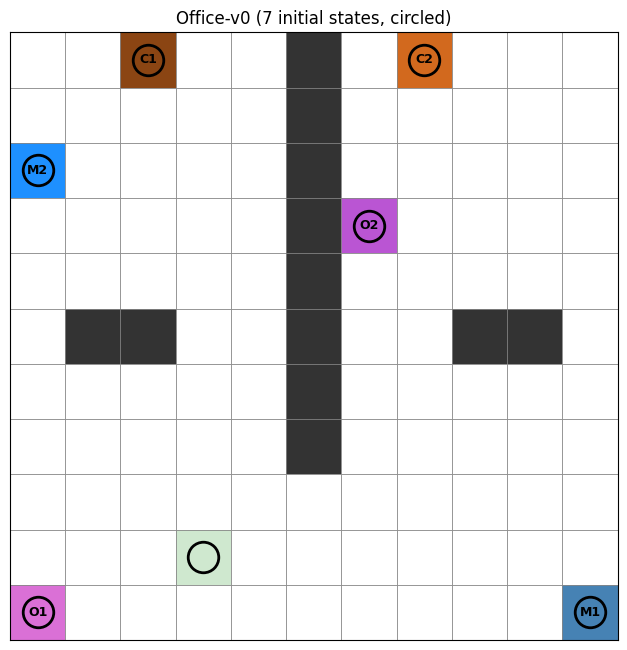

In [4]:
MAP = office_env.core.MAP
height, width = MAP.shape

color_map = {"X": "#333333", "_": "#cfe8cf", " ": "#ffffff"}
object_colors = {
    "C1": "#8B4513", "C2": "#D2691E",
    "M1": "#4682B4", "M2": "#1E90FF",
    "O1": "#DA70D6", "O2": "#BA55D3",
}
color_map.update(object_colors)


def cell_center(r, c):
    return c + 0.5, height - r - 1 + 0.5


def draw_domain(ax):
    for r in range(height):
        for c in range(width):
            sym = MAP[r, c]
            color = color_map.get(sym, "#ffffff")
            rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5)
            ax.add_patch(rect)
            if sym not in ("X", " ", "_"):
                ax.text(*cell_center(r, c), sym, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
for s in office_env.core.initial:
    x, y = cell_center(*s)
    ax.plot(x, y, marker="o", markersize=22, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=5)
ax.set_title(f"Office-v0 ({len(office_env.core.initial)} initial states, circled)")
plt.tight_layout()
plt.show()

## Exact building blocks

In [5]:
def office_step_deterministic(env, s, a):
    """One exact transition under Office's deterministic dynamics (random_act_prob=0.0)."""
    env.reset(options={"state": s})
    _, phi, terminated, _truncated, _ = env.step(a)
    return tuple(env.core.state), phi, terminated


office_states = [(r, c) for r in range(height) for c in range(width) if MAP[r, c] != "X"]
office_state_idx = {s: i for i, s in enumerate(office_states)}
n_office_states = len(office_states)
n_actions = office_env.action_space.n


def office_policy_iteration_from_any(w, gamma=GAMMA):
    """Ground truth for exit-state values: object cells are valid non-absorbing SOURCE
    states too (still terminal as destinations)."""
    policy = {s: 0 for s in office_states}
    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in office_states:
            qs = []
            for a in range(n_actions):
                ns, phi, term = office_step_deterministic(office_env, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def office_solve_task_exact(w, gamma=GAMMA):
    """Exact SF table Psi(s,a) for every action/state -- a separate vector-valued
    evaluation of the fixed policy (reusing the scalar V would silently broadcast it
    across all feature dims instead of the real vector, see notes/adaptive_basis.tex)."""
    policy, _ = office_policy_iteration_from_any(w, gamma)
    A, b = np.eye(n_office_states), np.zeros((n_office_states, d))
    for s in office_states:
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(office_env, s, policy[s])
        b[i] = phi
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[office_state_idx[s]] for s in office_states}

    psi = {}
    for s in office_states:
        table = np.zeros((n_actions, d))
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            table[a] = phi if term else phi + gamma * V_vec[ns]
        psi[s] = table
    return psi


def office_bellman_gap_from_any(w, V, gamma=GAMMA):
    """One full Bellman backup over the REAL 4-action space against a candidate V --
    no ground truth needed to trust a zero gap."""
    gaps = {}
    for s in office_states:
        qs = []
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
        gaps[s] = max(qs) - V[s]
    return gaps


def own_greedy_actions_any(sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in office_states}


def meta_policy_iteration_from_any(w, Pi_base, W_base, gamma=GAMMA):
    """Exact policy iteration over the meta-MDP whose actions are which of the k base
    policies' own action to take, solved for fresh-starting at ANY state."""
    own_actions = [own_greedy_actions_any(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    meta_policy = {s: 0 for s in office_states}

    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}

        stable = True
        for s in office_states:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = office_step_deterministic(office_env, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, own_actions


def meta_policy_iteration_certified(w, Pi_base, W_base, gamma=GAMMA, cert_tol=1e-6):
    """Compose from the CURRENT base; certify with one Bellman backup; fall back to an
    exact solve + grow the base if the certificate fails."""
    if Pi_base:
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        worst_gap = max(office_bellman_gap_from_any(w, V, gamma).values())
    else:
        worst_gap = np.inf
    if worst_gap > cert_tol:
        psi_new = office_solve_task_exact(w, gamma)
        Pi_base = Pi_base + [psi_new]
        W_base = W_base + [w]
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        fell_back = True
    else:
        fell_back = False
    return meta_policy, V, own_actions, Pi_base, W_base, fell_back

## The FSA task and ground truth

In [6]:
from fsa.fsa import FiniteStateAutomaton

symbols_to_phi = {sym: i for i, sym in enumerate(PHI_OBJ_TYPES)}
fsa = FiniteStateAutomaton(symbols_to_phi)
fsa.add_state("u0")
fsa.add_state("u1")
fsa.add_state("u2")
fsa.add_state("u3")
fsa.add_transition("u0", "u1", ["C1", "C2"])  # get coffee
fsa.add_transition("u1", "u2", ["M1", "M2"])  # then mail
fsa.add_transition("u2", "u3", ["O1", "O2"])  # then office (u3 terminal)

exit_states = office_env.core.exit_states


def meta_fsa_value_iteration(fsa, Pi_base, W_base, exit_states_map, gamma=GAMMA, num_iters=100, tol=1e-10):
    """Standard FSA-RM-VI (Infante et al., `SFFSAValueIteration.traverse`): backward
    value iteration over the automaton graph against a FIXED, already-complete basis."""
    U = fsa.states
    W = np.zeros((len(U), d))
    n_sweeps = 0
    for _ in range(num_iters):
        n_sweeps += 1
        W_old = W.copy()
        for uidx, u in enumerate(U):
            if fsa.is_terminal(u):
                continue
            total = np.zeros(d)
            for vidx, v in enumerate(U):
                if not fsa.graph.has_edge(u, v):
                    continue
                w_uv = np.zeros(d)
                propositions = fsa.get_predicate((u, v))
                idxs = [fsa.symbols_to_phi[p] for p in propositions]
                if fsa.is_terminal(v):
                    w_uv[idxs] = 1.0
                else:
                    for idx in idxs:
                        e = exit_states_map[idx]
                        _, V_e, _ = meta_policy_iteration_from_any(W[vidx], Pi_base, W_base, gamma)
                        w_uv[idx] = V_e[e]
                total += w_uv
            W[uidx] = total
        if np.allclose(W, W_old, atol=tol):
            break
    return {u: W[i] for i, u in enumerate(U)}, n_sweeps


def fsa_transition(u, idx):
    for v in fsa.get_neighbors(u):
        propositions = fsa.get_predicate((u, v))
        idxs = [fsa.symbols_to_phi[p] for p in propositions]
        if idx in idxs:
            return v
    return u


def product_step(s, u, a):
    """One exact transition in the product MDP (grid state x automaton state): sparse
    +1 reward exactly when this step completes the task."""
    ns, phi, term_single = office_step_deterministic(office_env, s, a)
    if term_single:
        idx = int(np.argmax(phi))
        v = fsa_transition(u, idx)
        return ns, v, (1.0 if fsa.is_terminal(v) else 0.0), fsa.is_terminal(v)
    return ns, u, 0.0, False


live_u = [u for u in fsa.states if not fsa.is_terminal(u)]
prod_states = [(s, u) for u in live_u for s in office_states]
prod_idx = {su: i for i, su in enumerate(prod_states)}
n_prod = len(prod_states)


def product_policy_iteration(gamma=GAMMA):
    """The TRUE optimum for the whole non-Markovian task: full policy iteration over
    the real product space, no basis restriction, no FSA-graph shortcut."""
    policy = {su: 0 for su in prod_states}
    while True:
        A, b = np.eye(n_prod), np.zeros(n_prod)
        for su in prod_states:
            s, u = su
            i = prod_idx[su]
            ns, v, r, done = product_step(s, u, policy[su])
            b[i] = r
            if not done:
                A[i, prod_idx[(ns, v)]] -= gamma
        val = np.linalg.solve(A, b)
        V = {su: val[prod_idx[su]] for su in prod_states}

        stable = True
        for su in prod_states:
            s, u = su
            qs = []
            for a in range(n_actions):
                ns, v, r, done = product_step(s, u, a)
                qs.append(r + (0.0 if done else gamma * V[(ns, v)]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[su]
            policy[su] = best_a
        if stable:
            return policy, V


def product_evaluate_policy(action_fn, gamma=GAMMA):
    A, b = np.eye(n_prod), np.zeros(n_prod)
    for su in prod_states:
        s, u = su
        i = prod_idx[su]
        ns, v, r, done = product_step(s, u, action_fn(s, u))
        b[i] = r
        if not done:
            A[i, prod_idx[(ns, v)]] -= gamma
    val = np.linalg.solve(A, b)
    return {su: val[prod_idx[su]] for su in prod_states}


policy_opt_prod, V_opt_prod = product_policy_iteration()
START_STATE = (9, 3)  # the '_' cell -- designated start
print(f"product MDP: {n_prod} live (state, automaton-state) pairs")
print(f"V*(start={START_STATE}, u0) = {V_opt_prod[(START_STATE, 'u0')]:.4f}")

product MDP: 327 live (state, automaton-state) pairs
V*(start=(9, 3), u0) = 0.8097


## Certified-RM-VI (ours): adaptive certified basis

In [7]:
def meta_fsa_value_iteration_adaptive(fsa, exit_states_map, gamma=GAMMA, num_iters=100, tol=1e-10):
    """meta_fsa_value_iteration, but the base starts EMPTY and grows on demand via
    meta_policy_iteration_certified. Certify-or-Grow is only defined for a query weight
    on the L1 simplex (notes/adaptive_basis.tex), so every W[v] is normalized before
    composing and the result rescaled by the same L1 norm afterward (homogeneity of the
    restricted value function in w). One certify call per EDGE, not per proposition --
    meta_policy_iteration_from_any/certified already returns a full value dict over
    every state, so all of an edge's exit-state values come from a single call."""
    U = fsa.states
    W = np.zeros((len(U), d))
    Pi_base, W_base = [], []
    n_composed, n_fallback, n_sweeps = 0, 0, 0

    def certify_at(w_raw):
        nonlocal Pi_base, W_base, n_composed, n_fallback
        norm = np.linalg.norm(w_raw, ord=1)
        if norm < 1e-12:
            return {s: 0.0 for s in office_states}
        w_hat = w_raw / norm
        _, V_hat, _, Pi_base, W_base, fell_back = meta_policy_iteration_certified(
            w_hat, Pi_base, W_base, gamma)
        n_fallback += fell_back
        n_composed += not fell_back
        return {s: norm * v for s, v in V_hat.items()}

    for _ in range(num_iters):
        n_sweeps += 1
        W_old = W.copy()
        for uidx, u in enumerate(U):
            if fsa.is_terminal(u):
                continue
            total = np.zeros(d)
            for vidx, v in enumerate(U):
                if not fsa.graph.has_edge(u, v):
                    continue
                w_uv = np.zeros(d)
                propositions = fsa.get_predicate((u, v))
                idxs = [fsa.symbols_to_phi[p] for p in propositions]
                if fsa.is_terminal(v):
                    w_uv[idxs] = 1.0
                else:
                    V_scaled = certify_at(W[vidx])  # one call for the whole edge
                    for idx in idxs:
                        e = exit_states_map[idx]
                        w_uv[idx] = V_scaled[e]
                total += w_uv
            W[uidx] = total
        if np.allclose(W, W_old, atol=tol):
            break

    for uidx, u in enumerate(U):
        if fsa.is_terminal(u):
            continue
        certify_at(W[uidx])

    return {u: W[i] for i, u in enumerate(U)}, Pi_base, W_base, n_composed, n_fallback, n_sweeps


t0 = time.perf_counter()
W_fsa_adaptive, Pi_base_final, W_base_final, n_composed, n_fallback, n_sweeps = \
    meta_fsa_value_iteration_adaptive(fsa, exit_states)
t_adaptive_once = time.perf_counter() - t0

print(f"converged in {n_sweeps} sweeps, {t_adaptive_once:.2f}s")
print(f"final basis size: {len(Pi_base_final)}  (composed calls: {n_composed}, fallback exact solves: {n_fallback})")
print("fallback weights (in order added):")
for w in W_base_final:
    print("  ", w.round(4))

converged in 4 sweeps, 2.79s
final basis size: 3  (composed calls: 5, fallback exact solves: 3)
fallback weights (in order added):
   [0.  0.  0.5 0.5 0.  0. ]
   [0.    0.    0.    0.    0.495 0.505]
   [0.5276 0.4724 0.     0.     0.     0.    ]


In [8]:
U = fsa.states
W = np.zeros((len(U), d))
Pi_base_dbg, W_base_dbg = [], []
sweep = 0
while True:
    sweep += 1
    W_old = W.copy()
    for uidx, u in enumerate(U):
        if fsa.is_terminal(u):
            continue
        total = np.zeros(d)
        for vidx, v in enumerate(U):
            if not fsa.graph.has_edge(u, v):
                continue
            w_uv = np.zeros(d)
            propositions = fsa.get_predicate((u, v))
            idxs = [fsa.symbols_to_phi[p] for p in propositions]
            if fsa.is_terminal(v):
                w_uv[idxs] = 1.0
            else:
                norm = np.linalg.norm(W[vidx], ord=1)
                if norm < 1e-12:
                    V_scaled = {s: 0.0 for s in office_states}
                else:
                    w_hat = W[vidx] / norm
                    _, V_hat, _, Pi_base_dbg, W_base_dbg, _ = meta_policy_iteration_certified(w_hat, Pi_base_dbg, W_base_dbg, GAMMA)
                    V_scaled = {s: norm * v for s, v in V_hat.items()}
                for idx in idxs:
                    e = exit_states[idx]
                    w_uv[idx] = V_scaled[e]
            total += w_uv
        W[uidx] = total
    for uidx, u in enumerate(U):
        print(f"sweep {sweep}  W[{u}] = {W[uidx].round(4)}")
    if np.allclose(W, W_old, atol=1e-10):
        break

sweep 1  W[u0] = [0. 0. 0. 0. 0. 0.]
sweep 1  W[u1] = [0. 0. 0. 0. 0. 0.]
sweep 1  W[u2] = [0. 0. 1. 1. 0. 0.]
sweep 1  W[u3] = [0. 0. 0. 0. 0. 0.]


sweep 2  W[u0] = [0. 0. 0. 0. 0. 0.]
sweep 2  W[u1] = [0.     0.     0.     0.     0.9135 0.9321]
sweep 2  W[u2] = [0. 0. 1. 1. 0. 0.]
sweep 2  W[u3] = [0. 0. 0. 0. 0. 0.]


sweep 3  W[u0] = [0.9044 0.8097 0.     0.     0.     0.    ]
sweep 3  W[u1] = [0.     0.     0.     0.     0.9135 0.9321]
sweep 3  W[u2] = [0. 0. 1. 1. 0. 0.]
sweep 3  W[u3] = [0. 0. 0. 0. 0. 0.]


sweep 4  W[u0] = [0.9044 0.8097 0.     0.     0.     0.    ]
sweep 4  W[u1] = [0.     0.     0.     0.     0.9135 0.9321]
sweep 4  W[u2] = [0. 0. 1. 1. 0. 0.]
sweep 4  W[u3] = [0. 0. 0. 0. 0. 0.]


In [9]:
meta_policies_per_u = {}
for u in fsa.states:
    if fsa.is_terminal(u):
        continue
    mp, _, oa = meta_policy_iteration_from_any(W_fsa_adaptive[u], Pi_base_final, W_base_final)
    meta_policies_per_u[u] = (mp, oa)


def composed_action_adaptive(s, u):
    mp, oa = meta_policies_per_u[u]
    return oa[mp[s]][s]


V_composed_adaptive = product_evaluate_policy(composed_action_adaptive)
n_mismatch_adaptive = sum(not np.isclose(V_opt_prod[su], V_composed_adaptive[su], atol=1e-6) for su in prod_states)

print(f"V*(start={START_STATE}, u0)          = {V_opt_prod[(START_STATE, 'u0')]:.4f}")
print(f"V^adaptive(start={START_STATE}, u0)  = {V_composed_adaptive[(START_STATE, 'u0')]:.4f}")
print(f"mismatched (state, automaton-state) pairs: {n_mismatch_adaptive}/{n_prod}")

V*(start=(9, 3), u0)          = 0.8097
V^adaptive(start=(9, 3), u0)  = 0.8097
mismatched (state, automaton-state) pairs: 2/327


## Standard CCS (Infante et al.): SFOLS discovers the full CCS, then traverse

In [10]:
import io
import contextlib
import random


def gpi_action(rng, state, w, sf_tables):
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)
    action_values = values.max(axis=0)
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))


class TabularGPIAgent:
    """Adapter so OLS.next_w's GPI-based rollout scoring can be reused with tabular
    policies. Office is deterministic, so a rollout carries no sampling error beyond
    tie-breaking (which cannot change the achieved value)."""

    def __init__(self, env, sf_tables, gamma, seed=0):
        self.env = env
        self.sf_tables = sf_tables
        self.gamma = gamma
        self.rng = random.Random(seed)

    def eval(self, obs, w):
        state = tuple(self.env.core.state)
        return gpi_action(self.rng, state, w, self.sf_tables)


def office_sfols_exact(gamma=GAMMA, epsilon=0.01, max_iterations=23):
    """OLS (Optimistic Linear Support) + TabularGPIAgent's rollout-based priority,
    solving every discovered CCS point exactly via office_solve_task_exact."""
    ols = OLS(m=d, epsilon=epsilon)
    solved = {}
    gpi_agent = TabularGPIAgent(office_env, [], gamma, seed=SEED)

    n_solves = 0
    it = 0
    w = ols.next_w()
    while w is not None and it < max_iterations:
        it += 1
        w = np.asarray(w, dtype=np.float64)
        key = tuple(np.round(w, 6))
        if key not in solved:
            solved[key] = office_solve_task_exact(w, gamma)
            n_solves += 1
        psi_table = solved[key]
        vecs = [psi_table[tuple(s0)][int(np.argmax(psi_table[tuple(s0)] @ w))] for s0 in office_env.core.initial]
        value = np.mean(vecs, axis=0)
        ols.add_solution(value, w)
        gpi_agent.sf_tables = [solved[tuple(np.round(cw, 6))] for cw in ols.ccs_weights]
        w = ols.next_w(gpi_agent=gpi_agent, env=office_env, rep_eval=len(office_env.core.initial))

    Pi_full = [solved[tuple(np.round(np.asarray(w), 6))] for w in ols.ccs_weights]
    W_full = [np.asarray(w) for w in ols.ccs_weights]
    return Pi_full, W_full, n_solves


def office_sfols_then_iterate(fsa, exit_states_map, gamma=GAMMA):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        Pi_full, W_full, n_solves = office_sfols_exact(gamma)
    W_fsa_full, n_sweeps_standard = meta_fsa_value_iteration(fsa, Pi_full, W_full, exit_states_map, gamma)
    return W_fsa_full, Pi_full, W_full, n_solves, n_sweeps_standard

## Fair timing comparison: standard vs. certified-adaptive

In [11]:
N_REPEATS = 1

standard_times = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    W_fsa_standard, Pi_full, W_full, standard_n_solves, n_sweeps_standard = office_sfols_then_iterate(fsa, exit_states)
    standard_times.append(time.perf_counter() - t0)

adaptive_times = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    W_fsa_adapt, Pi_base_adapt, W_base_adapt, n_comp, n_fb, n_sw = meta_fsa_value_iteration_adaptive(fsa, exit_states)
    adaptive_times.append(time.perf_counter() - t0)

n_distinct_adaptive = len({tuple(w.round(6)) for w in W_base_adapt})

print(f"SFOLS-discovered CCS size: {len(W_full)} points ({standard_n_solves} exact solves), traverse converged in {n_sweeps_standard} sweeps")
print(f"adaptive converged in {n_sw} sweeps")
print(f"\nstandard  (SFOLS discovers CCS, then iterate): median {np.median(standard_times) * 1000:8.1f}ms   "
      f"basis={standard_n_solves} exact solves (CCS size={len(W_full)})")
print(f"adaptive  (certified, grown on demand):         median {np.median(adaptive_times) * 1000:8.1f}ms   "
      f"basis={len(Pi_base_adapt)} exact solves ({n_distinct_adaptive} distinct)")
print(f"speedup: {np.median(standard_times) / np.median(adaptive_times):.2f}x")

meta_policies_std = {}
for u in fsa.states:
    if fsa.is_terminal(u):
        continue
    mp, _, oa = meta_policy_iteration_from_any(W_fsa_standard[u], Pi_full, W_full)
    meta_policies_std[u] = (mp, oa)


def composed_action_standard(s, u):
    mp, oa = meta_policies_std[u]
    return oa[mp[s]][s]


V_composed_standard = product_evaluate_policy(composed_action_standard)
n_mismatch_standard = sum(not np.isclose(V_opt_prod[su], V_composed_standard[su], atol=1e-6) for su in prod_states)

print(f"\nstandard mismatches vs. ground truth: {n_mismatch_standard}/{n_prod}")
print(f"adaptive mismatches vs. ground truth: {n_mismatch_adaptive}/{n_prod}")

SFOLS-discovered CCS size: 17 points (17 exact solves), traverse converged in 4 sweeps
adaptive converged in 4 sweeps

standard  (SFOLS discovers CCS, then iterate): median  47136.8ms   basis=17 exact solves (CCS size=17)
adaptive  (certified, grown on demand):         median   3159.3ms   basis=3 exact solves (3 distinct)
speedup: 14.92x



standard mismatches vs. ground truth: 2/327
adaptive mismatches vs. ground truth: 2/327


## Comparison plot: composed FSA rollout, standard vs. certified-adaptive

standard and adaptive rollouts follow the identical grid-state path: True


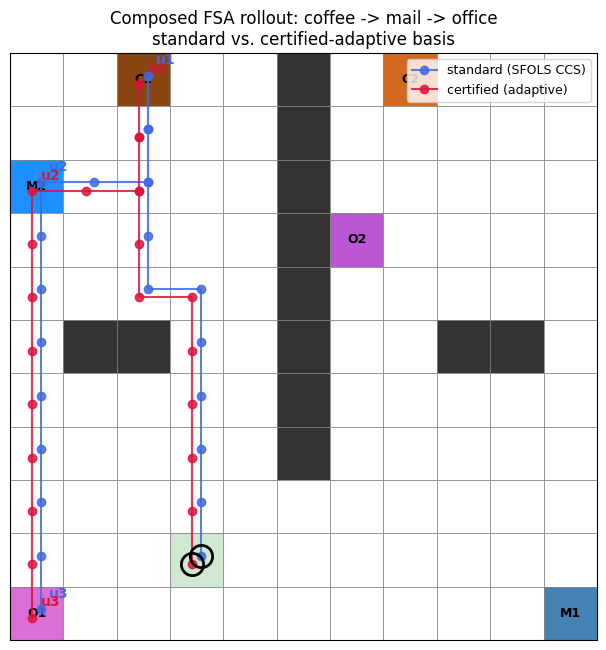

In [12]:
def rollout_fsa(action_fn, start_state, max_steps=60):
    s, u = start_state, "u0"
    trace = [(s, u)]
    for _ in range(max_steps):
        a = action_fn(s, u)
        ns, phi, term_single = office_step_deterministic(office_env, s, a)
        v = fsa_transition(u, int(np.argmax(phi))) if term_single else u
        s, u = ns, v
        trace.append((s, u))
        if fsa.is_terminal(u):
            break
    return trace


trace_standard = rollout_fsa(composed_action_standard, START_STATE)
trace_adaptive = rollout_fsa(composed_action_adaptive, START_STATE)
same_path = [s for s, u in trace_standard] == [s for s, u in trace_adaptive]
print(f"standard and adaptive rollouts follow the identical grid-state path: {same_path}")

fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)


def plot_trace(ax, trace, color, label, offset=0.0):
    xs = [cell_center(*s)[0] + offset for s, u in trace]
    ys = [cell_center(*s)[1] + offset for s, u in trace]
    ax.plot(xs, ys, "-o", color=color, markersize=6, zorder=6, label=label, alpha=0.85)
    ax.plot(xs[0], ys[0], marker="o", markersize=16, markerfacecolor="none",
            markeredgecolor="black", markeredgewidth=2, zorder=7)
    prev_u = trace[0][1]
    for s, u in trace:
        if u != prev_u:
            x, y = cell_center(*s)
            ax.annotate(u, (x + offset, y + offset), textcoords="offset points", xytext=(6, 8),
                        fontsize=10, fontweight="bold", color=color)
            prev_u = u


plot_trace(ax, trace_standard, "royalblue", "standard (SFOLS CCS)", offset=0.08)
plot_trace(ax, trace_adaptive, "crimson", "certified (adaptive)", offset=-0.08)
ax.legend(loc="upper right", fontsize=9)
ax.set_title("Composed FSA rollout: coffee -> mail -> office\nstandard vs. certified-adaptive basis")
plt.tight_layout()
plt.show()

## GPI vs. metapolicy as the base grows: the canonical corner-weight basis

A cleaner test of what composing buys you, isolated from OLS/CCS-discovery entirely.
The base is the `d=6` **canonical corner-weight policies** `pi(e_1), ..., pi(e_6)`
(each exactly solved for one unit-vector weight), added in that fixed order -- at
basis size `k`, the base is `{pi(e_1), ..., pi(e_k)}`. Three ways to combine them,
all using the SAME k SF tables:

- **GPI (full action set)**: the standard, textbook combination (Barreto et al., Eq. 4)
  -- at every state, `argmax` over ALL 4 actions of `max_j Psi_j(s,a).w`. Even at k=1
  this is a real one-step policy-improvement of pi(e_1) against the query weight w, so
  it generally does NOT reduce to "follow pi(e_1)" -- it can pick a different first
  action whenever some other action's one-step lookahead beats pi(e_1)'s own choice.
- **One-shot election (restricted)**: at every state, compare only the k policies' OWN
  actions (`own_greedy_actions_any(Psi_j, w_j)`, i.e. what pi_j does under ITS OWN
  training weight) by their SF value under the query weight w, and pick the single best
  one -- ONE greedy pass, not iterated. With k=1 there is nothing to elect between, so
  this reduces EXACTLY to "follow pi(e_1) everywhere," by construction.
- **Metapolicy (restricted, iterated)**: the same restricted per-state menu as the
  election, but instead of stopping after one greedy pass, run real policy iteration
  (`meta_policy_iteration_from_any`) to a fixed point. At k=1 there is still only one
  candidate, so this ALSO reduces exactly to "follow pi(e_1) everywhere" -- identical
  to the election at k=1, by the same construction.

So at k=1, election and metapolicy necessarily coincide (both degenerate to plain
pi(e_1)), while GPI is a separate quantity that can sit above OR below them depending
on whether pi(e_1)'s own action already happens to be the full-action-set argmax under
w. Because election and metapolicy search the exact same restricted menu and differ
only in whether they iterate, metapolicy >= election is GUARANTEED at every k (ordinary
policy-improvement theorem, same action space). GPI is not nested with either restricted
method -- it can beat or lose to them, since it has access to actions neither of them
would ever consider, but each base policy's SF table was only ever trained against its
own corner weight. Whether metapolicy actually reaches EXACT optimality at k=6 is an
open empirical question here, not a theorem -- office_bellman_gap_from_any-based checks
earlier in this notebook found small residual mismatches even with a basis this size,
so we report the real numbers below rather than assume convergence.

In [13]:
def office_evaluate_policy_scalar(action_fn, w, gamma=GAMMA):
    """Exact scalar value of an arbitrary FIXED (state -> action) policy under w, via
    linear solve -- no ground-truth optimum needed."""
    A, b = np.eye(n_office_states), np.zeros(n_office_states)
    for s in office_states:
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(office_env, s, action_fn(s))
        b[i] = phi @ w
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    v = np.linalg.solve(A, b)
    return {s: v[office_state_idx[s]] for s in office_states}


def office_gpi_full_actions(Pi, w):
    """Standard GPI (Barreto et al., Eq. 4): argmax over the FULL action set, using
    max_j Psi_j(s,a).w for every action a -- not restricted to any policy's own action."""
    actions = {}
    for s in office_states:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(n_actions)]
        actions[s] = int(np.argmax(vals))
    return actions


def office_election_actions(Pi_base, W_base, w):
    """One-shot restricted election: compare the k base policies' OWN actions by their
    SF value under the query weight w, pick the best per state -- a single greedy pass,
    NOT iterated. At k=1 there's nothing to elect between, so this is exactly pi(e_1)."""
    own_actions = [own_greedy_actions_any(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    actions = {}
    for s in office_states:
        vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
        best_j = int(np.argmax(vals))
        actions[s] = own_actions[best_j][s]
    return actions


def office_gpi_value(Pi_snapshot, w, gamma=GAMMA):
    actions = office_gpi_full_actions(Pi_snapshot, w)
    return office_evaluate_policy_scalar(lambda s: actions[s], w, gamma)


def office_election_value(Pi_base, W_base, w, gamma=GAMMA):
    actions = office_election_actions(Pi_base, W_base, w)
    return office_evaluate_policy_scalar(lambda s: actions[s], w, gamma)


def office_metapolicy_value(Pi_base, W_base, w, gamma=GAMMA):
    _, V, _ = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
    return V


def office_mean_value(value_fn, test_weights):
    """value_fn(w) -> {state: scalar value}. Averages at office_env.core.initial
    (the 'different starting conditions'), then across all test weights."""
    vals = []
    for w in test_weights:
        V = value_fn(w)
        vals.append(np.mean([V[tuple(s0)] for s0 in office_env.core.initial]))
    return float(np.mean(vals))


N_TEST_WEIGHTS = 150
rng_w = np.random.default_rng(SEED)
test_weights = [rng_w.dirichlet(np.ones(d)) for _ in range(N_TEST_WEIGHTS)]

t0 = time.perf_counter()
optimal_mean = office_mean_value(lambda w: office_policy_iteration_from_any(w)[1], test_weights)
print(f"optimal_mean = {optimal_mean:.4f}  ({time.perf_counter() - t0:.1f}s, {N_TEST_WEIGHTS} test weights)")

t0 = time.perf_counter()
Pi_canon, W_canon = [], []
for i in range(d):
    w_i = np.zeros(d)
    w_i[i] = 1.0
    Pi_canon.append(office_solve_task_exact(w_i))
    W_canon.append(w_i)
print(f"solved the {d} canonical corner policies in {time.perf_counter() - t0:.1f}s")

optimal_mean = 0.3573  (98.1s, 150 test weights)


solved the 6 canonical corner policies in 4.8s


k=1: GPI=0.2093  election=0.1367  metapolicy=0.1367


k=2: GPI=0.2696  election=0.2206  metapolicy=0.2206


k=3: GPI=0.2972  election=0.2578  metapolicy=0.2578


k=4: GPI=0.3152  election=0.3012  metapolicy=0.3012


k=5: GPI=0.3371  election=0.3292  metapolicy=0.3292


k=6: GPI=0.3573  election=0.3573  metapolicy=0.3573

computed in 513.3s


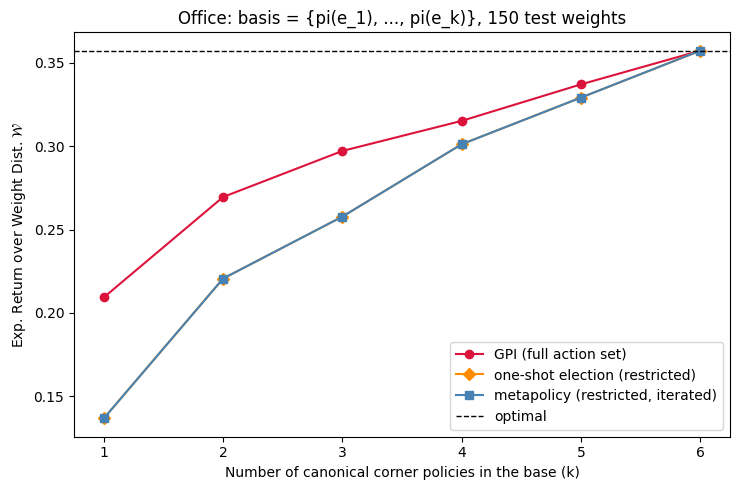


k=1 election == metapolicy: 0.136713 == 0.136713
metapolicy >= election at every k: True
metapolicy gap to optimal at k=6: 0.000000
GPI gap to optimal at k=6:        0.000000


In [14]:
ks = np.arange(1, d + 1)
gpi_curve, election_curve, metapolicy_curve = [], [], []

t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    gpi_curve.append(office_mean_value(lambda w, Pi_k=Pi_k: office_gpi_value(Pi_k, w), test_weights))
    election_curve.append(office_mean_value(lambda w, Pi_k=Pi_k, W_k=W_k: office_election_value(Pi_k, W_k, w), test_weights))
    metapolicy_curve.append(office_mean_value(lambda w, Pi_k=Pi_k, W_k=W_k: office_metapolicy_value(Pi_k, W_k, w), test_weights))
    print(f"k={k}: GPI={gpi_curve[-1]:.4f}  election={election_curve[-1]:.4f}  metapolicy={metapolicy_curve[-1]:.4f}")
print(f"\ncomputed in {time.perf_counter() - t0:.1f}s")

assert np.allclose(election_curve[0], metapolicy_curve[0]), \
    "k=1 election and metapolicy should coincide exactly (nothing to elect between)"

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ks, gpi_curve, marker="o", ms=6, color="crimson", label="GPI (full action set)")
ax.plot(ks, election_curve, marker="D", ms=6, color="darkorange", label="one-shot election (restricted)")
ax.plot(ks, metapolicy_curve, marker="s", ms=6, color="steelblue", label="metapolicy (restricted, iterated)")
ax.axhline(optimal_mean, color="black", ls="--", lw=1, label="optimal")
ax.set_xlabel("Number of canonical corner policies in the base (k)")
ax.set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
ax.set_title(f"Office: basis = {{pi(e_1), ..., pi(e_k)}}, {N_TEST_WEIGHTS} test weights")
ax.set_xticks(ks)
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nk=1 election == metapolicy: {election_curve[0]:.6f} == {metapolicy_curve[0]:.6f}")
print(f"metapolicy >= election at every k: {all(m >= e - 1e-9 for m, e in zip(metapolicy_curve, election_curve))}")
print(f"metapolicy gap to optimal at k={d}: {optimal_mean - metapolicy_curve[-1]:.6f}")
print(f"GPI gap to optimal at k={d}:        {optimal_mean - gpi_curve[-1]:.6f}")

## Pool-feedback: does composing a certified metapolicy back into GPI's pool close the gap?

Port of `SFOLS/03_adaptive_basis.ipynb` Part 7 to Office. The k=1..5 rows above are
exactly the regime that experiment was designed for and DST's ceiling effect ruled
out: `metapolicy < GPI` with real headroom (e.g. k=1: GPI=0.2093 vs metapolicy=0.1367).
The question is whether feeding a *certified* metapolicy's full SF table back into the
pool -- so GPI gets to use it too, not just the k canonical corner policies -- closes
some of that gap, and whether doing so stays cheap.

Two deliberate differences from the DST version, both to isolate the effect cleanly:
- **No fallback exact solve.** `meta_policy_iteration_certified` (defined earlier in
  this notebook) falls back to `office_solve_task_exact` whenever the certificate
  fails. Here we skip that entirely -- an uncertified query weight is just left out of
  the pool. This measures how far *free* composition alone can grow the pool from a
  FIXED starting basis, isolated from OLS/CCS discovery (matching this section's own
  framing above), not a full Certify-or-Grow run.
- **The pool is grown from a separate weight sample, not `test_weights` itself**, so
  the final GPI-over-pool evaluation on `test_weights` is never evaluated on the same
  weights used to build it.

In [15]:
def office_meta_policy_sf(meta_policy, own_actions, gamma=GAMMA):
    """Vector-valued SF of the metapolicy's OWN chosen action at every state -- the
    Office analogue of SFOLS/03_adaptive_basis.ipynb's meta_policy_sf. One linear
    solve, the same system meta_policy_iteration_from_any already builds every sweep,
    just with a vector instead of scalar right-hand side (b[i] = phi, not phi @ w)."""
    A, b = np.eye(n_office_states), np.zeros((n_office_states, d))
    for s in office_states:
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(office_env, s, own_actions[meta_policy[s]][s])
        b[i] = phi
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[office_state_idx[s]] for s in office_states}


def office_meta_policy_sf_full(meta_policy, own_actions, gamma=GAMMA, Psi_own=None):
    """Extends office_meta_policy_sf to a full (actions x features) table, GPI-ready --
    same construction as SFOLS/03_adaptive_basis.ipynb's meta_policy_sf_full. The
    recursive part is already solved (Psi_own); extending to every OTHER action is a
    single non-recursive O(|S||A|) backup, no new linear solve. Pass a precomputed
    Psi_own to skip re-solving when the caller already needed it (e.g. for a gap check
    or bookkeeping)."""
    if Psi_own is None:
        Psi_own = office_meta_policy_sf(meta_policy, own_actions, gamma)
    table = {}
    for s in office_states:
        full = np.zeros((n_actions, d))
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            full[a] = phi if term else phi + gamma * Psi_own[ns]
        table[s] = full
    return table

In [16]:
def office_grow_pool_with_metapolicy_feedback(Pi_base, W_base, build_weights, gamma=GAMMA, cert_tol=1e-6):
    """Process build_weights in order; for each, certify a metapolicy against the
    CURRENT pool (meta_policy_iteration_from_any + office_bellman_gap_from_any) and,
    when certified, fold its full SF table back into the pool
    (office_meta_policy_sf_full) -- no fallback exact solve on certify failure (see
    this section's markdown for why). Timing is split the same way as the DST version:
    the meta_policy_sf linear solve is needed for ANY certify check's bookkeeping
    regardless of pooling, so only the final non-recursive backup+append is charged as
    pool-feedback's own incremental cost."""
    Pi_base, W_base = list(Pi_base), list(W_base)
    n_certified = n_uncertified = n_added = 0
    t_restricted_pi = t_meta_sf_solve = t_pool_feedback = 0.0

    for w in build_weights:
        t0 = time.perf_counter()
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        worst_gap = max(office_bellman_gap_from_any(w, V, gamma).values())
        t_restricted_pi += time.perf_counter() - t0
        certified = worst_gap <= cert_tol

        if certified:
            n_certified += 1
            t0 = time.perf_counter()
            Psi_own = office_meta_policy_sf(meta_policy, own_actions, gamma)
            t_meta_sf_solve += time.perf_counter() - t0

            t0 = time.perf_counter()
            Pi_base.append(office_meta_policy_sf_full(meta_policy, own_actions, gamma, Psi_own=Psi_own))
            W_base.append(w)
            t_pool_feedback += time.perf_counter() - t0
            n_added += 1
        else:
            n_uncertified += 1

    stats = dict(n_certified=n_certified, n_uncertified=n_uncertified, n_added=n_added)
    timing = dict(t_restricted_pi=t_restricted_pi, t_meta_sf_solve=t_meta_sf_solve, t_pool_feedback=t_pool_feedback)
    return Pi_base, W_base, stats, timing


N_BUILD_WEIGHTS = 30
rng_build = np.random.default_rng(SEED + 1)  # separate sample from test_weights -- see markdown
build_weights = [rng_build.dirichlet(np.ones(d)) for _ in range(N_BUILD_WEIGHTS)]

pooled_curve, pool_sizes, pool_stats_by_k, pool_timing_by_k = [], [], [], []
t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    Pi_grown, W_grown, stats_k, timing_k = office_grow_pool_with_metapolicy_feedback(Pi_k, W_k, build_weights)
    pooled_curve.append(office_mean_value(lambda w, Pi=Pi_grown: office_gpi_value(Pi, w), test_weights))
    pool_sizes.append(len(Pi_grown))
    pool_stats_by_k.append(stats_k)
    pool_timing_by_k.append(timing_k)
    print(f"k={k}: pool grew {k} -> {len(Pi_grown)}  "
          f"({stats_k['n_added']}/{N_BUILD_WEIGHTS} build weights certified & added)  "
          f"pooled+GPI={pooled_curve[-1]:.4f}")
print(f"\ncomputed in {time.perf_counter() - t0:.1f}s")

k=1: pool grew 1 -> 4  (3/30 build weights certified & added)  pooled+GPI=0.2093


k=2: pool grew 2 -> 10  (8/30 build weights certified & added)  pooled+GPI=0.2696


k=3: pool grew 3 -> 17  (14/30 build weights certified & added)  pooled+GPI=0.2972


k=4: pool grew 4 -> 23  (19/30 build weights certified & added)  pooled+GPI=0.3152


k=5: pool grew 5 -> 29  (24/30 build weights certified & added)  pooled+GPI=0.3371


k=6: pool grew 6 -> 36  (30/30 build weights certified & added)  pooled+GPI=0.3573

computed in 336.4s


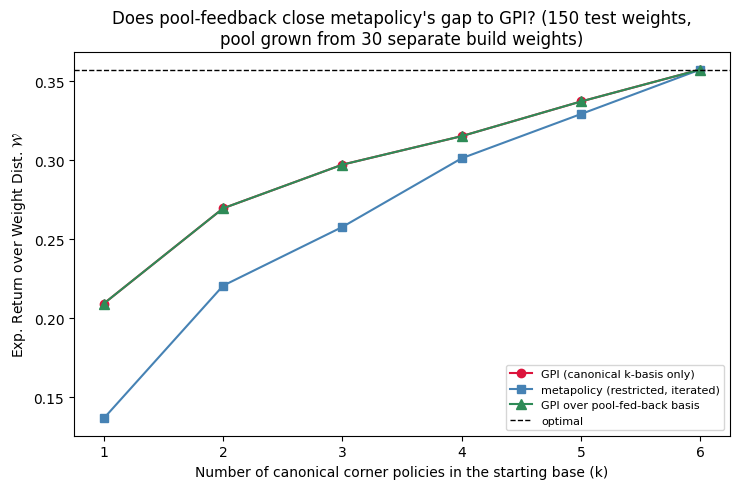

  k    GPI gap   metapolicy gap   pooled gap   % of metapolicy-GPI gap closed
  1     0.1480           0.2206       0.1480                            32.9%
  2     0.0878           0.1367       0.0878                            35.8%
  3     0.0602           0.0996       0.0602                            39.6%
  4     0.0421           0.0561       0.0421                            25.0%
  5     0.0202           0.0282       0.0202                            28.2%
  6     0.0000           0.0000       0.0000                             nan%

is pool-feedback actually cheap here too? (summed across all k)
restricted PI + gap check (baseline cost, shared)                :   308.38s  ( 98.7%)
meta_policy_sf linear solve (needed for ANY certify check anyway):     0.81s  (  0.3%)
extend to full table + append to pool (the ONLY new cost)        :     3.34s  (  1.1%)
total                                                            :   312.53s

incremental pool-feedback cost per policy actually

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ks, gpi_curve, marker="o", ms=6, color="crimson", label="GPI (canonical k-basis only)")
ax.plot(ks, metapolicy_curve, marker="s", ms=6, color="steelblue", label="metapolicy (restricted, iterated)")
ax.plot(ks, pooled_curve, marker="^", ms=7, color="seagreen", label="GPI over pool-fed-back basis")
ax.axhline(optimal_mean, color="black", ls="--", lw=1, label="optimal")
ax.set_xlabel("Number of canonical corner policies in the starting base (k)")
ax.set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
ax.set_title(f"Does pool-feedback close metapolicy's gap to GPI? ({N_TEST_WEIGHTS} test weights,\n"
             f"pool grown from {N_BUILD_WEIGHTS} separate build weights)")
ax.set_xticks(ks)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

gap_metapolicy = [optimal_mean - v for v in metapolicy_curve]
gap_gpi = [optimal_mean - v for v in gpi_curve]
gap_pooled = [optimal_mean - v for v in pooled_curve]
closed_frac = [(gm - gp) / gm if gm > 1e-9 else float("nan") for gm, gp in zip(gap_metapolicy, gap_pooled)]

print(f"{'k':>3} {'GPI gap':>10} {'metapolicy gap':>16} {'pooled gap':>12} {'% of metapolicy-GPI gap closed':>32}")
for k, gm, gg, gp, cf in zip(ks, gap_metapolicy, gap_gpi, gap_pooled, closed_frac):
    print(f"{k:>3} {gg:>10.4f} {gm:>16.4f} {gp:>12.4f} {100*cf:>31.1f}%")

sep = "=" * 70
print(f"\n{sep}")
print("is pool-feedback actually cheap here too? (summed across all k)")
print(sep)
total_timing = {key: sum(t[key] for t in pool_timing_by_k) for key in pool_timing_by_k[0]}
total_added = sum(s["n_added"] for s in pool_stats_by_k)
total_t = sum(total_timing.values())
labels = {
    "t_restricted_pi": "restricted PI + gap check (baseline cost, shared)",
    "t_meta_sf_solve": "meta_policy_sf linear solve (needed for ANY certify check anyway)",
    "t_pool_feedback": "extend to full table + append to pool (the ONLY new cost)",
}
for key, v in total_timing.items():
    print(f"{labels[key]:65s}: {v:8.2f}s  ({100*v/total_t:5.1f}%)")
print(f"{'total':65s}: {total_t:8.2f}s")
if total_added > 0:
    print(f"\nincremental pool-feedback cost per policy actually added to the pool: "
          f"{1000*total_timing['t_pool_feedback']/total_added:.2f} ms")

## Cost of ALWAYS getting the exact optimum: iterating pi^hyb

`notes/adaptive_basis.tex`'s bootstrap fix defines `pi^hyb(s) = argmax_a [phi(s,a).w +
gamma * E[V_meta(s')]]` -- one full-action-set greedy step against `V_meta`. That single
step is provably >= `V_meta` and its one-step bootstrap dominates GPI's own, but it is
NOT itself `V*_w` in general. Getting exact optimality out of it means *iterating* it:
evaluate `pi^hyb` exactly, take another full-action-set greedy step, repeat. That is
just ordinary policy iteration over the FULL action set, warm-started at `V_meta`
instead of at Algorithm 1's current cold start (`policy = 0 everywhere`). Since policy
iteration converges to `V*_w` from ANY start, this always works -- the only question is
*how many sweeps* it costs, each one as expensive as a sweep of the cold-start fallback
itself (a full policy evaluation + a full-action-set greedy pass over all 109 states).
So the payoff is not "optimal for free," it is "optimal in fewer exact-solve sweeps,
shrinking as the basis (and hence `V_meta`) gets closer to `V*_w`."

We measure this directly: for k=1..6 canonical corner policies, warm-start the SAME
policy-iteration loop used everywhere else in this notebook at the metapolicy's own
action policy (`office_metapolicy_action_policy`, i.e. `pi^hyb`'s starting point) and
count sweeps to the fixed point, against a cold start from scratch. 1 sweep means
`pi^hyb` was already stable, i.e. GPI's own full-action lookahead against `V_meta`
found nothing to improve -- a real, checkable certificate, not an assumption.

In [18]:
def office_policy_iteration_warmstart(w, init_policy, gamma=GAMMA):
    """Identical loop to office_policy_iteration_from_any, but seeded at an arbitrary
    initial policy instead of 'always action 0', and counting sweeps to the fixed
    point. Warm-starting at V_meta's own action policy and running this to convergence
    IS 'iterate pi^hyb': the first sweep's greedy step against the warm start's V is
    exactly pi^hyb; further sweeps are the same operator applied again."""
    policy = dict(init_policy)
    n_iters = 0
    while True:
        n_iters += 1
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in office_states:
            qs = []
            for a in range(n_actions):
                ns, phi, term = office_step_deterministic(office_env, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V, n_iters


def office_metapolicy_action_policy(Pi_base, W_base, w, gamma=GAMMA):
    """The metapolicy's actual (state -> real action) map -- V_meta's greedy policy,
    i.e. pi^hyb's warm start."""
    meta_policy, _, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
    return {s: own_actions[meta_policy[s]][s] for s in office_states}


N_COST_WEIGHTS = 30
cost_test_weights = test_weights[:N_COST_WEIGHTS]
cold_policy0 = {s: 0 for s in office_states}

t0 = time.perf_counter()
cold_results = [office_policy_iteration_warmstart(w, cold_policy0) for w in cost_test_weights]
cold_iters = [n for _, _, n in cold_results]
print(f"cold start (Algorithm 1's current fallback): mean {np.mean(cold_iters):.2f} sweeps "
      f"(min {min(cold_iters)}, max {max(cold_iters)}), {time.perf_counter() - t0:.1f}s for {N_COST_WEIGHTS} weights")

warm_iters_by_k = []
t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    n_this_k = []
    for w, (_, V_cold, _) in zip(cost_test_weights, cold_results):
        init = office_metapolicy_action_policy(Pi_k, W_k, w)
        _, V_warm, n_iters = office_policy_iteration_warmstart(w, init)
        assert all(abs(V_warm[s] - V_cold[s]) < 1e-6 for s in office_states), \
            "warm- and cold-started policy iteration must converge to the SAME V*_w -- the fixed point is unique"
        n_this_k.append(n_iters)
    warm_iters_by_k.append(n_this_k)
    n_free = sum(1 for n in n_this_k if n == 1)
    print(f"k={k}: mean {np.mean(n_this_k):.2f} sweeps (min {min(n_this_k)}, max {max(n_this_k)}), "
          f"{n_free}/{N_COST_WEIGHTS} weights where pi^hyb was ALREADY stable (0 extra sweeps)")
print(f"\ncomputed in {time.perf_counter() - t0:.1f}s total")

cold start (Algorithm 1's current fallback): mean 16.13 sweeps (min 10, max 21), 25.0s for 30 weights


k=1: mean 14.10 sweeps (min 2, max 24), 0/30 weights where pi^hyb was ALREADY stable (0 extra sweeps)


k=2: mean 12.87 sweeps (min 2, max 24), 0/30 weights where pi^hyb was ALREADY stable (0 extra sweeps)


k=3: mean 12.07 sweeps (min 2, max 24), 0/30 weights where pi^hyb was ALREADY stable (0 extra sweeps)


k=4: mean 9.93 sweeps (min 2, max 24), 0/30 weights where pi^hyb was ALREADY stable (0 extra sweeps)


k=5: mean 7.03 sweeps (min 2, max 24), 0/30 weights where pi^hyb was ALREADY stable (0 extra sweeps)


k=6: mean 3.83 sweeps (min 2, max 10), 0/30 weights where pi^hyb was ALREADY stable (0 extra sweeps)

computed in 204.9s total


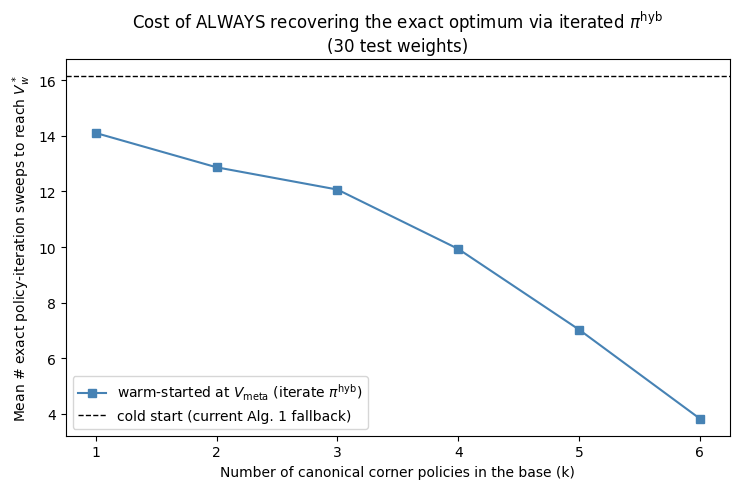

k=1: speedup over cold start = 1.14x  (mean sweeps 14.10 vs. cold 16.13)
k=2: speedup over cold start = 1.25x  (mean sweeps 12.87 vs. cold 16.13)
k=3: speedup over cold start = 1.34x  (mean sweeps 12.07 vs. cold 16.13)
k=4: speedup over cold start = 1.62x  (mean sweeps 9.93 vs. cold 16.13)
k=5: speedup over cold start = 2.29x  (mean sweeps 7.03 vs. cold 16.13)
k=6: speedup over cold start = 4.21x  (mean sweeps 3.83 vs. cold 16.13)


In [19]:
mean_warm = [np.mean(n) for n in warm_iters_by_k]
mean_cold = np.mean(cold_iters)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ks, mean_warm, marker="s", ms=6, color="steelblue",
        label=r"warm-started at $V_{\mathrm{meta}}$ (iterate $\pi^{\mathrm{hyb}}$)")
ax.axhline(mean_cold, color="black", ls="--", lw=1, label="cold start (current Alg. 1 fallback)")
ax.set_xlabel("Number of canonical corner policies in the base (k)")
ax.set_ylabel("Mean # exact policy-iteration sweeps to reach $V^*_w$")
ax.set_title(f"Cost of ALWAYS recovering the exact optimum via iterated $\\pi^{{\\mathrm{{hyb}}}}$\n"
             f"({N_COST_WEIGHTS} test weights)")
ax.set_xticks(ks)
ax.legend()
plt.tight_layout()
plt.show()

for k, n_this_k in zip(ks, warm_iters_by_k):
    print(f"k={k}: speedup over cold start = {mean_cold / np.mean(n_this_k):.2f}x  "
          f"(mean sweeps {np.mean(n_this_k):.2f} vs. cold {mean_cold:.2f})")